# PneumoniaMNIST – Klasyfikacja zdjęć rentgenowskich płuc w kierunku zapalenia płuc
**Przedmiot:** Uczenie Maszynowe w Diagnostyce Medycznej (Politechnika Krakowska)  
**Zespół:** Kamil Rayski, Miłosz Pabis  
**Zbiór danych:** [Kaggle: Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia) / PneumoniaMNIST ($n = 5\,856$ zdjęć RTG)

---
## 1. Wstęp i pobranie danych (`kagglehub`)
Celem projektu jest budowa, optymalizacja oraz wyjaśnialna ewaluacja modeli uczenia maszynowego (Regresja Logistyczna, Random Forest, SVM z jądrem RBF) oraz głębokiej sieci konwolucyjnej (`PneumoniaCNN` w PyTorch) do wykrywania zapalenia płuc na pediatrycznych zdjęciach RTG klatki piersiowej.

In [1]:
import os
import json
from config import DATA_DIR, DATASET_METADATA_PATH, FIGURES_DIR, KAGGLE_DATASET_ID, METRICS_SUMMARY_PATH
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Image as IPyImage
os.environ['KAGGLEHUB_CACHE'] = str(DATA_DIR)
import kagglehub

# Download latest version
path = kagglehub.dataset_download(KAGGLE_DATASET_ID)
print('Path to dataset files:', path)

Path to dataset files: data/datasets/paultimothymooney/chest-xray-pneumonia/versions/2


## 2. Eksploracyjna Analiza Danych (EDA)
Wczytujemy wygenerowane metadane wszystkich $5\,856$ zdjęć RTG, porównujemy oryginalny podział zbioru z repozytorium Kaggle (w którym podzbiór `val` liczył jedynie 16 zdjęć) ze skorygowanym podziałem stratyfikowanym zgodnym ze standardem **PneumoniaMNIST** ($4\,708$ `train`, $524$ `val`, $624$ `test`).

In [2]:
meta_df = pd.read_csv(DATASET_METADATA_PATH)
print(f'Łączna liczba zdjęć RTG: {len(meta_df)}')
print('\n--- Oryginalny podział (Kaggle) ---')
display(pd.crosstab(meta_df['orig_split'], meta_df['label_name'], margins=True))
print('\n--- Skorygowany podział stratyfikowany (standard PneumoniaMNIST) ---')
display(pd.crosstab(meta_df['split'], meta_df['label_name'], margins=True))
print('\n--- Podział etiologiczny (NORMAL vs BACTERIA vs VIRUS) ---')
display(meta_df['subtype'].value_counts().to_frame('Liczba zdjęć'))

Łączna liczba zdjęć RTG: 5856

--- Oryginalny podział (Kaggle) ---


label_name,NORMAL,PNEUMONIA,All
orig_split,,,
test,234,390,624
train,1341,3875,5216
val,8,8,16
All,1583,4273,5856



--- Skorygowany podział stratyfikowany (standard PneumoniaMNIST) ---


label_name,NORMAL,PNEUMONIA,All
split,,,
test,234,390,624
train,1214,3494,4708
val,135,389,524
All,1583,4273,5856



--- Podział etiologiczny (NORMAL vs BACTERIA vs VIRUS) ---


,Liczba zdjęć
subtype,
PNEUMONIA_BACTERIA,2780
NORMAL,1583
PNEUMONIA_VIRUS,1493


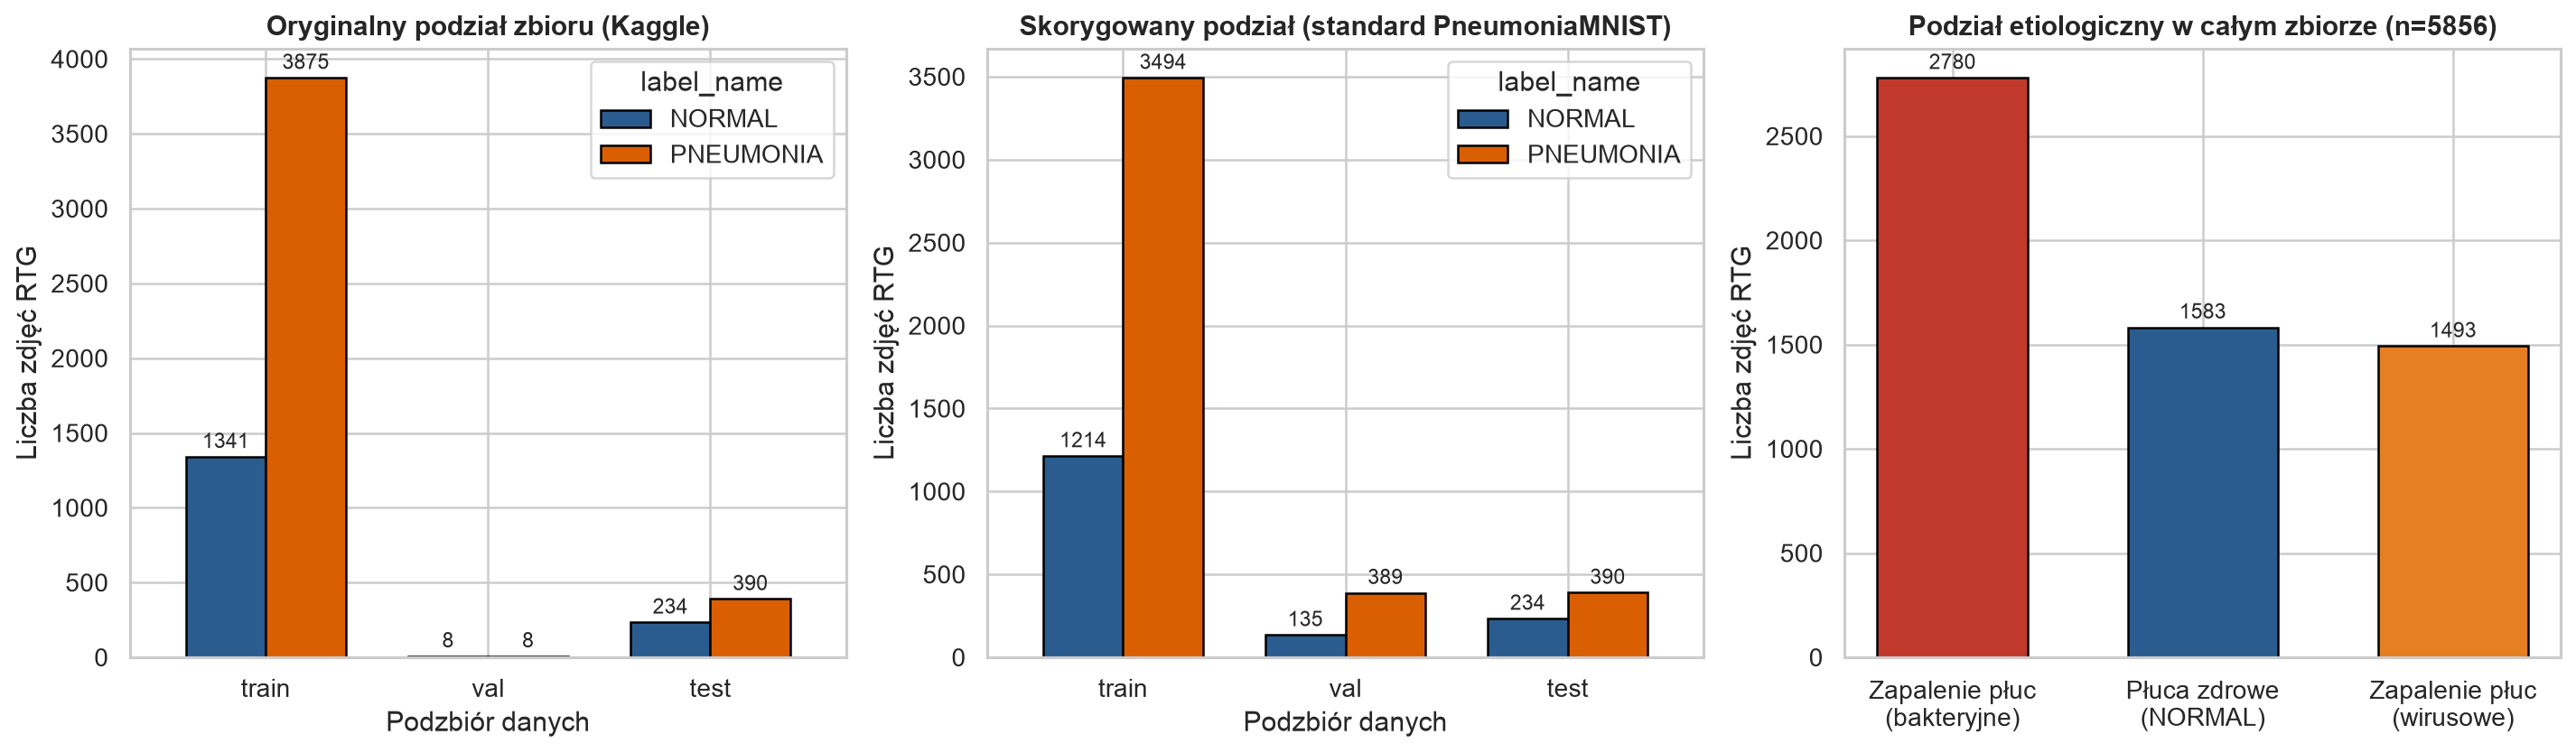

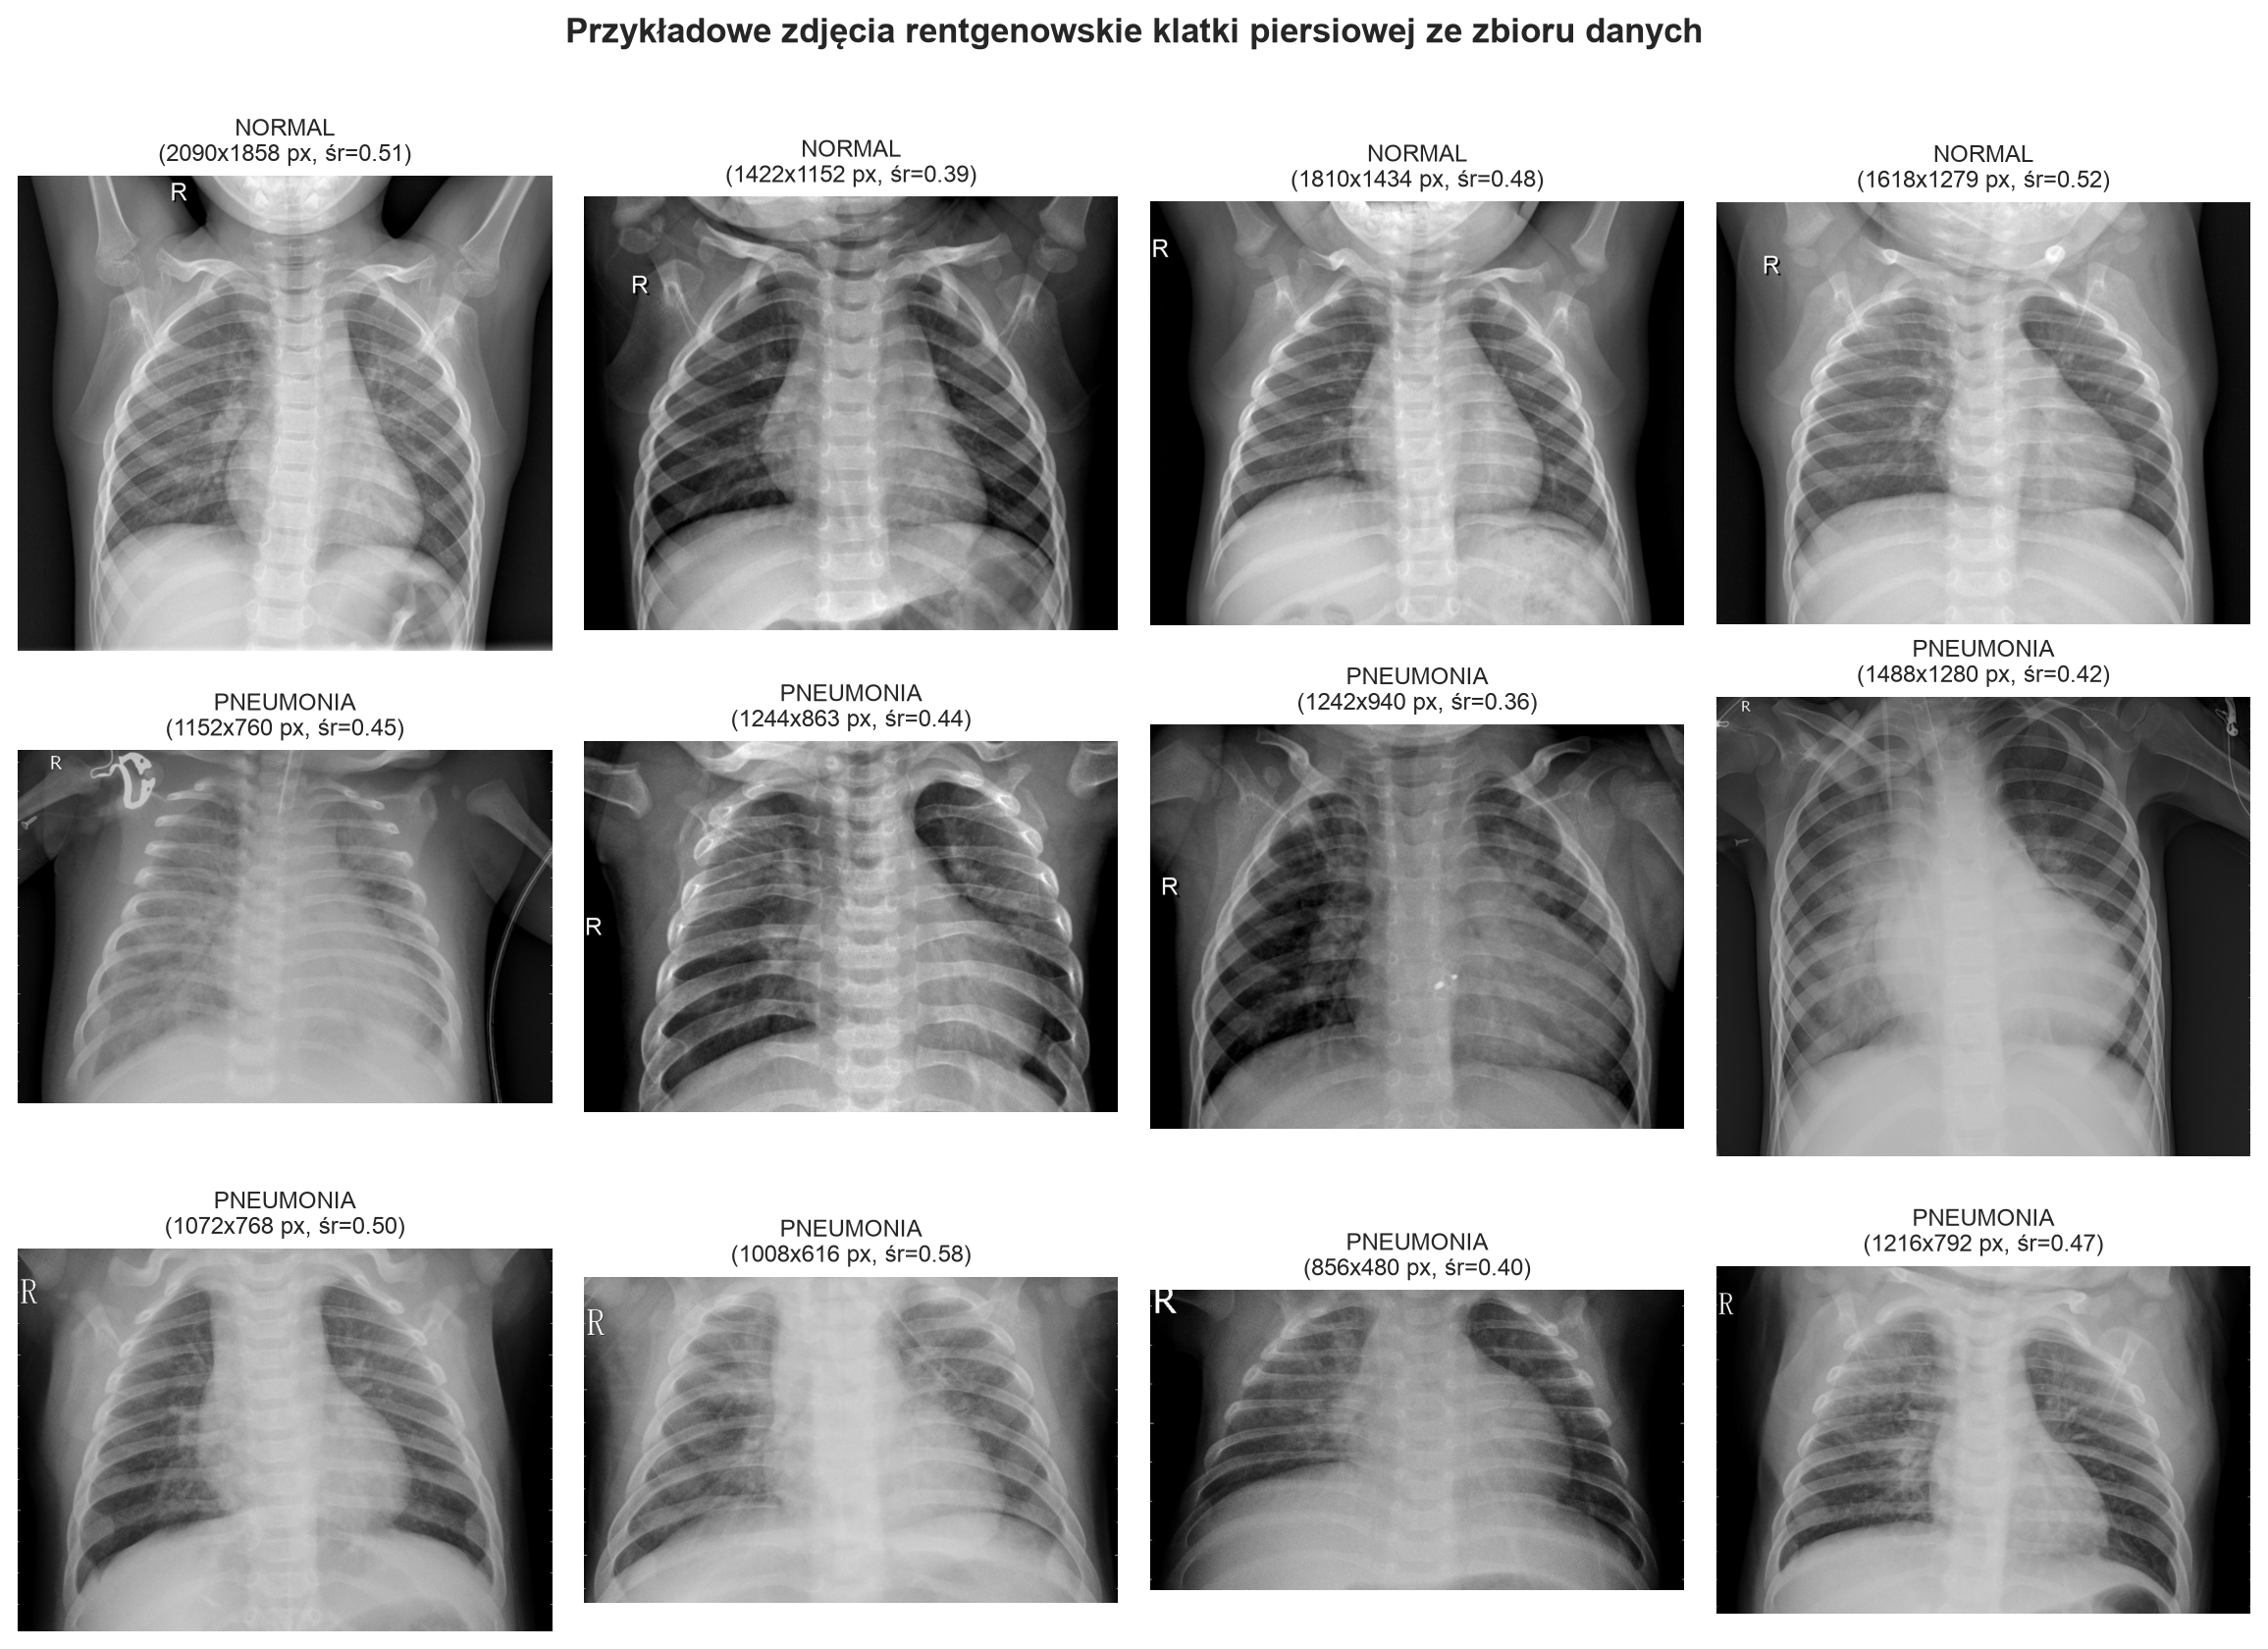

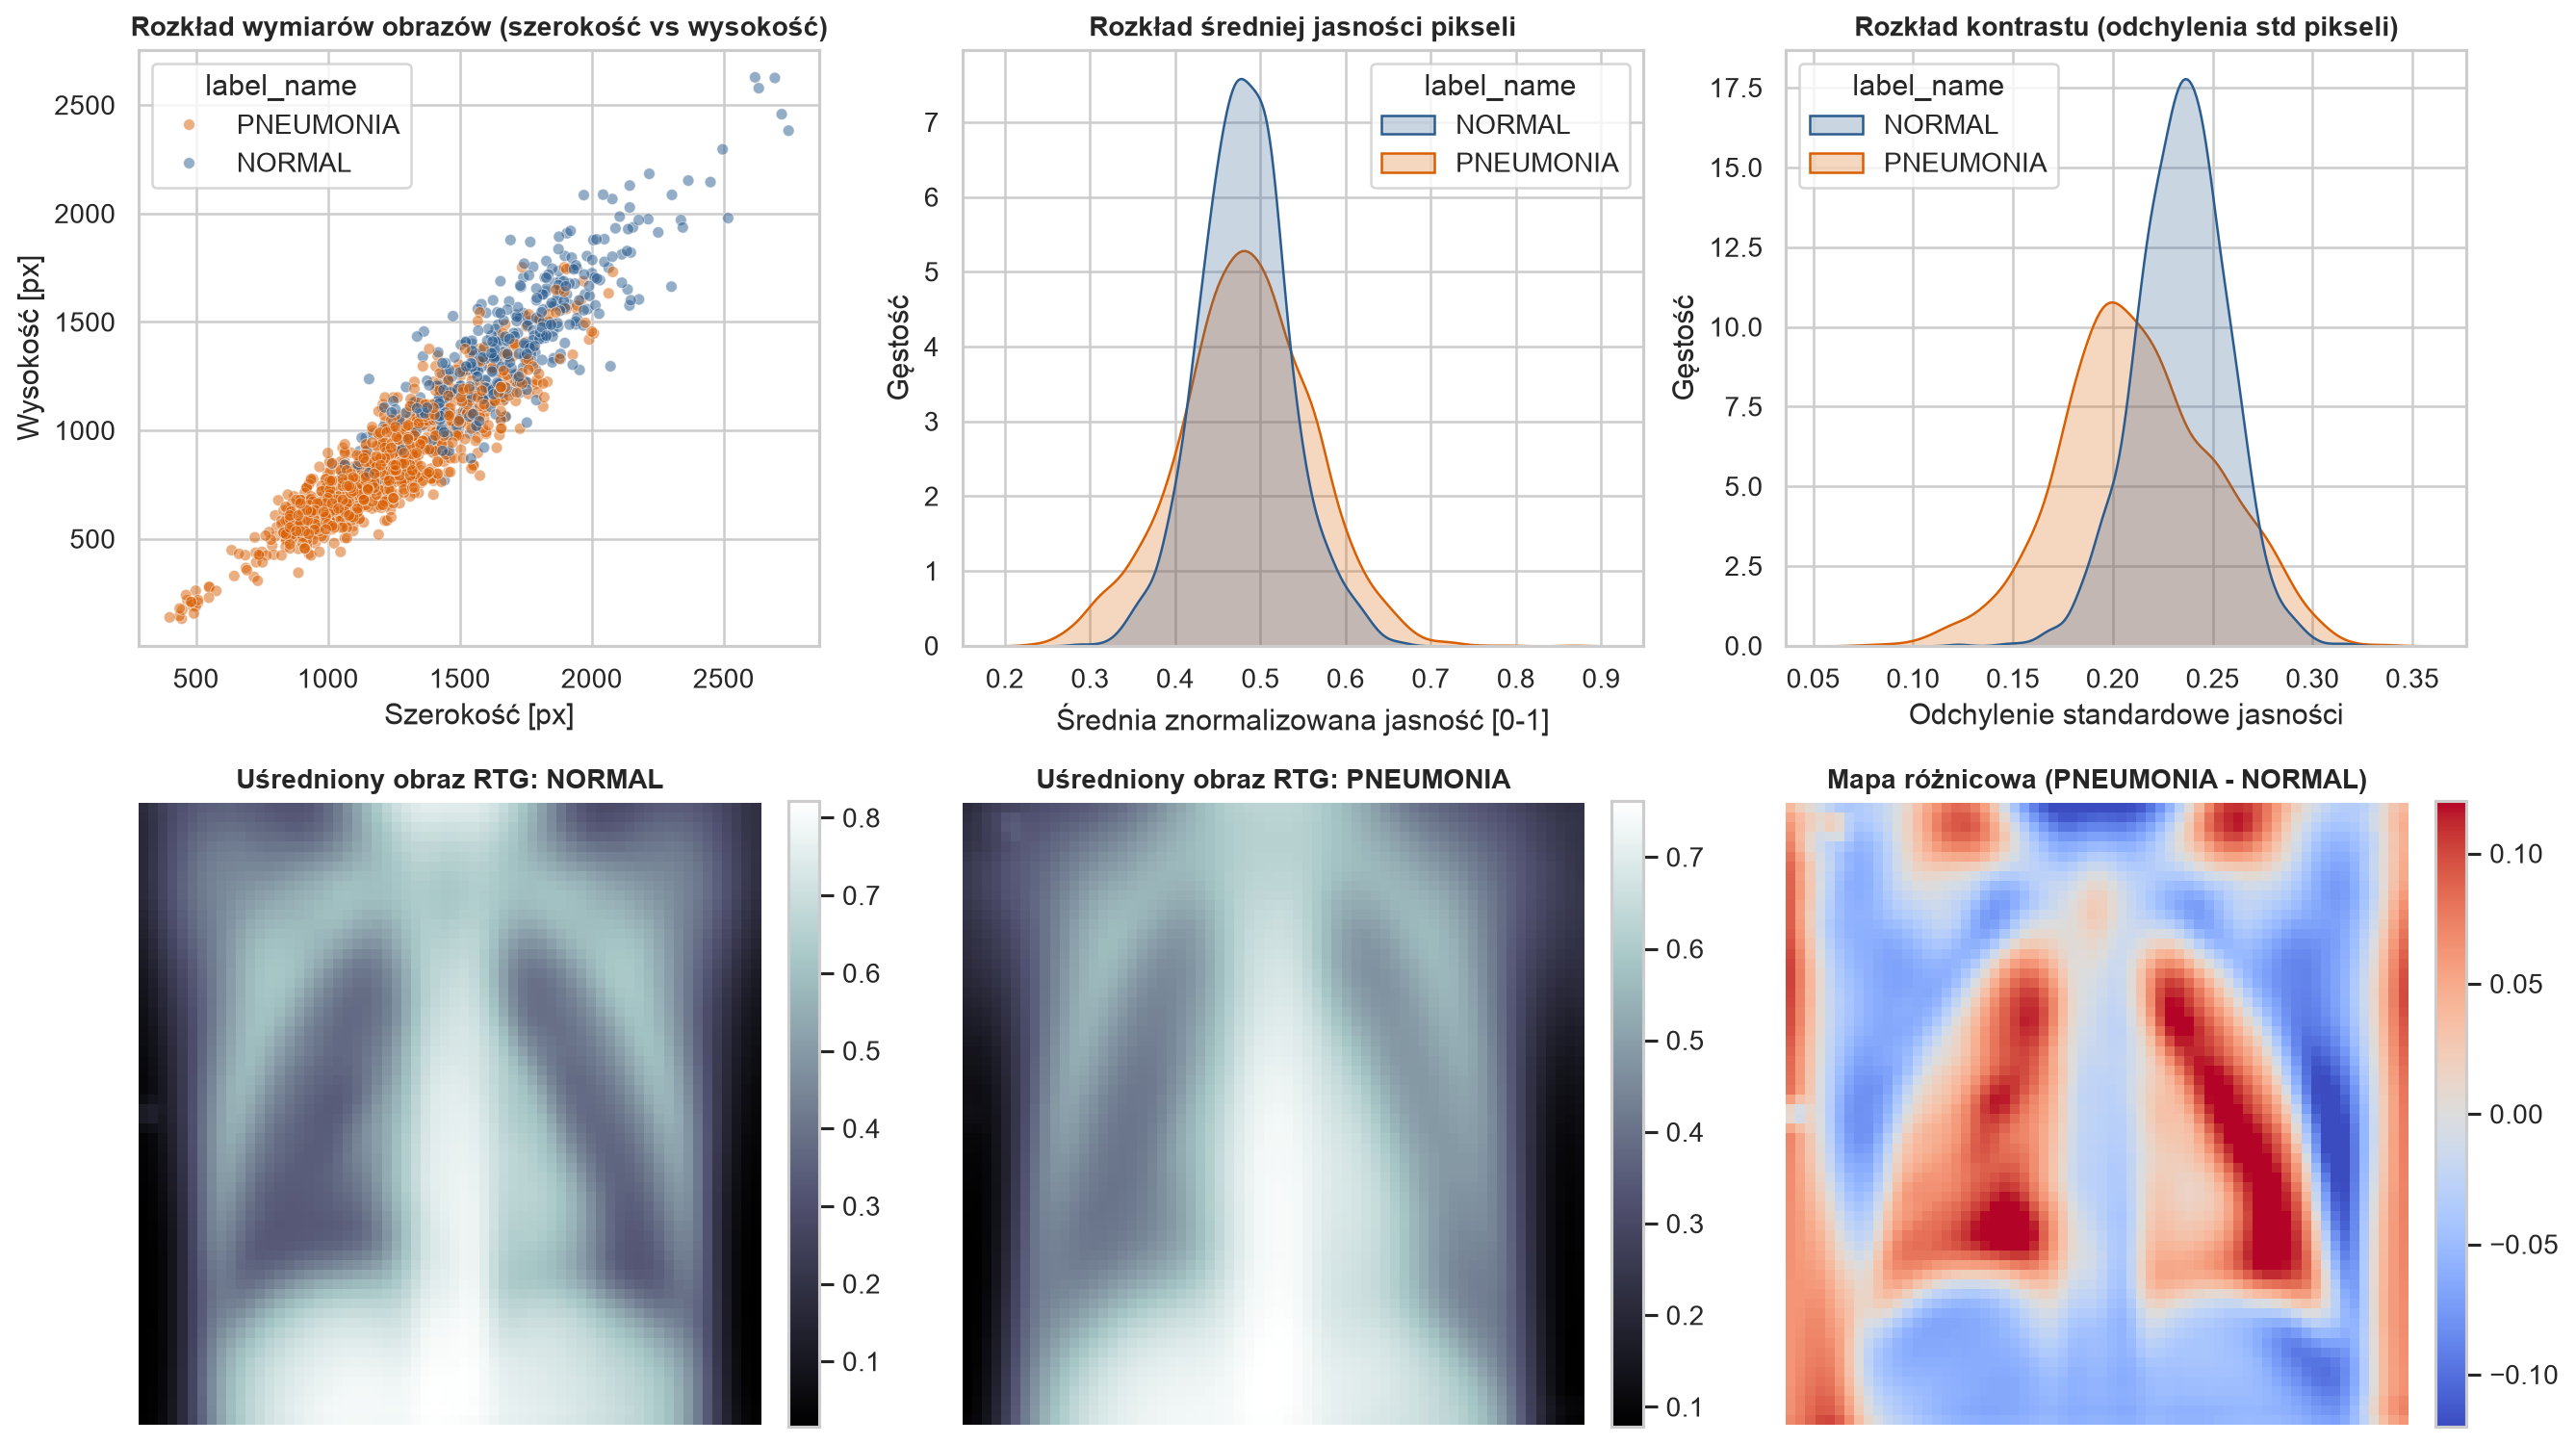

In [3]:
display(IPyImage(filename=str(FIGURES_DIR / 'fig1_class_distribution.png')))
display(IPyImage(filename=str(FIGURES_DIR / 'fig2_sample_xray_grid.png')))
display(IPyImage(filename=str(FIGURES_DIR / 'fig3_image_stats_eda.png')))

## 3. Przetwarzanie danych, Inżynieria Cech i Redukcja Wymiarowości (PCA)
- Dla klasycznych algorytmów ML obrazy zostały przeskalowane do wymiaru $64\times 64$ px ($4\,096$ cech) i uzupełnione o **17 cech domenowych** (statystyki kwantylowe, asymetria lewego i prawego płuca, strefy górna/środkowa/dolna, gradienty krawędziowe).
- Zastosowano transformację `StandardScaler` oraz **Analizę Składowych Głównych (PCA)** z $k=100$ komponentami (*Eigenlungs*), które wyjaśniają **91,47%** wariancji.

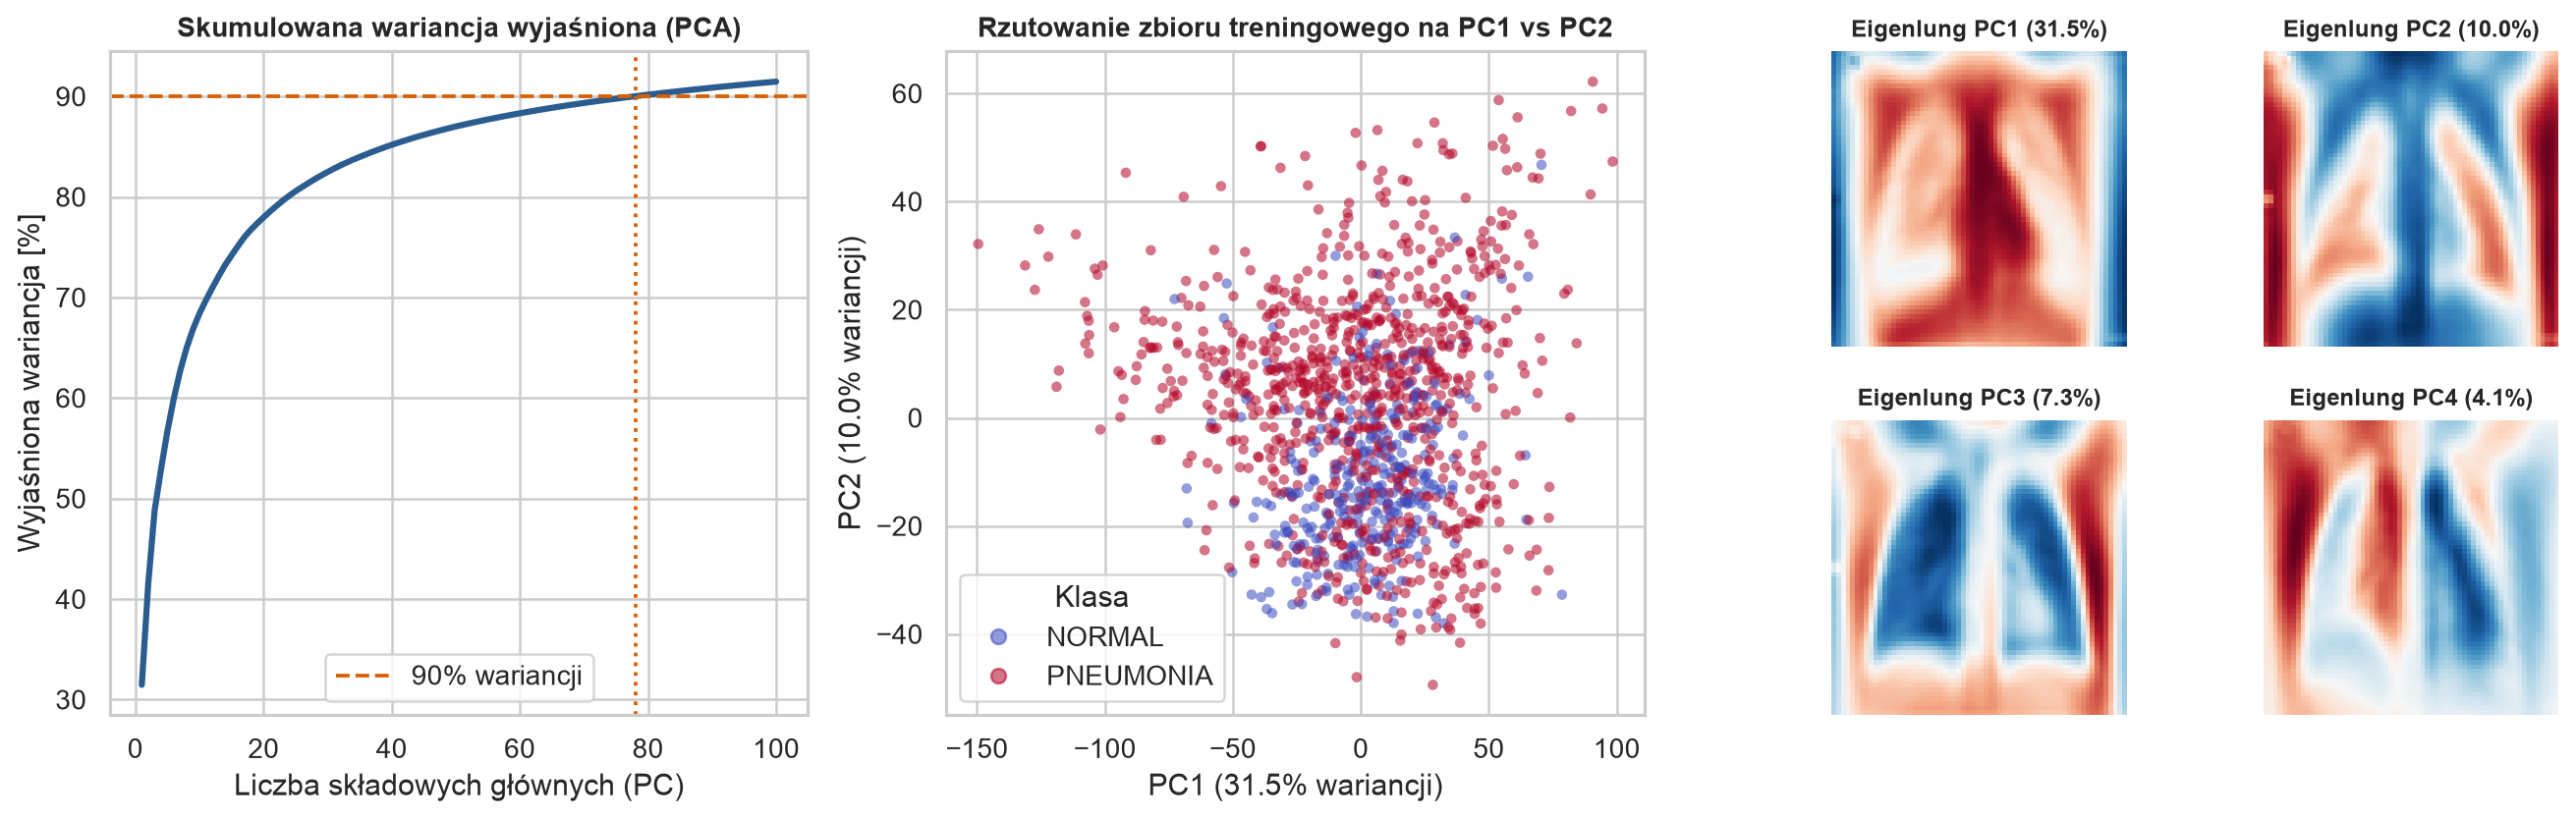

In [4]:
display(IPyImage(filename=str(FIGURES_DIR / 'fig4_pca_analysis.png')))

## 4. Modelowanie, Strojenie Hiperparametrów i Ewaluacja
Porównano cztery modele:
1. **Logistic Regression (PCA + 17 cech domenowych)** – `GridSearchCV` ($C=10.0$, `class_weight='balanced'`)
2. **Random Forest Classifier** – `GridSearchCV` (`n_estimators=300`, `max_depth=24`, `class_weight='balanced_subsample'`)
3. **SVM z jądrem RBF (PCA + 17 cech domenowych)** – `GridSearchCV` ($C=5.0$, `gamma='scale'`, `class_weight='balanced'`)
4. **PneumoniaCNN (PyTorch)** – 4-blokowa głęboka sieć konwolucyjna ($128\times 128$ px) z warstwami `BatchNorm2d`, `GlobalAveragePooling` i ważoną funkcją straty `CrossEntropyLoss`.

In [5]:
with open(METRICS_SUMMARY_PATH, 'r', encoding='utf-8') as f:
    summary = json.load(f)

rows = []
for m_name, res in summary['results_summary'].items():
    for split_key, split_label in [('val', 'Walidacyjny (n=524)'), ('test_default', 'Testowy (próg 0.50)'), ('test_calibrated', 'Testowy (kalibrowany)')]:
        d = res[split_key]
        rows.append({
            'Model': m_name,
            'Zbiór / Tryb': split_label,
            'Accuracy [%]': round(d['accuracy']*100, 2),
            'Balanced Acc [%]': round(d['balanced_accuracy']*100, 2),
            'Precision [%]': round(d['precision']*100, 2),
            'Recall [%]': round(d['recall']*100, 2),
            'Specificity [%]': round(d['specificity']*100, 2),
            'F1-score [%]': round(d['f1']*100, 2),
            'ROC-AUC': round(d['roc_auc'], 4),
            'PR-AUC': round(d['pr_auc'], 4)
        })
results_df = pd.DataFrame(rows)
display(results_df)

,Model,Zbiór / Tryb,Accuracy [%],Balanced Acc [%],Precision [%],Recall [%],Specificity [%],F1-score [%],ROC-AUC,PR-AUC
0,Logistic Regression,Walidacyjny (n=524),95.42,94.74,97.65,96.14,93.33,96.89,0.9892,0.9959
1,Logistic Regression,Testowy (próg 0.50),73.72,65.73,71.08,97.69,33.76,82.29,0.8869,0.9261
2,Logistic Regression,Testowy (kalibrowany),81.41,80.60,86.05,83.85,77.35,84.94,0.8869,0.9261
3,Random Forest,Walidacyjny (n=524),96.18,93.80,96.24,98.71,88.89,97.46,0.9901,0.9961
4,Random Forest,Testowy (próg 0.50),76.60,68.89,72.85,99.74,38.03,84.20,0.9349,0.9589
5,Random Forest,Testowy (kalibrowany),88.14,86.75,89.11,92.31,81.20,90.68,0.9349,0.9589
6,SVM (RBF),Walidacyjny (n=524),97.33,96.51,98.20,98.20,94.81,98.20,0.9955,0.9984
7,SVM (RBF),Testowy (próg 0.50),76.60,69.15,73.11,98.97,39.32,84.10,0.9039,0.9327
8,SVM (RBF),Testowy (kalibrowany),82.69,82.74,88.95,82.56,82.91,85.64,0.9039,0.9327
9,PneumoniaCNN (PyTorch),Walidacyjny (n=524),98.09,97.99,99.22,98.20,97.78,98.71,0.9980,0.9993


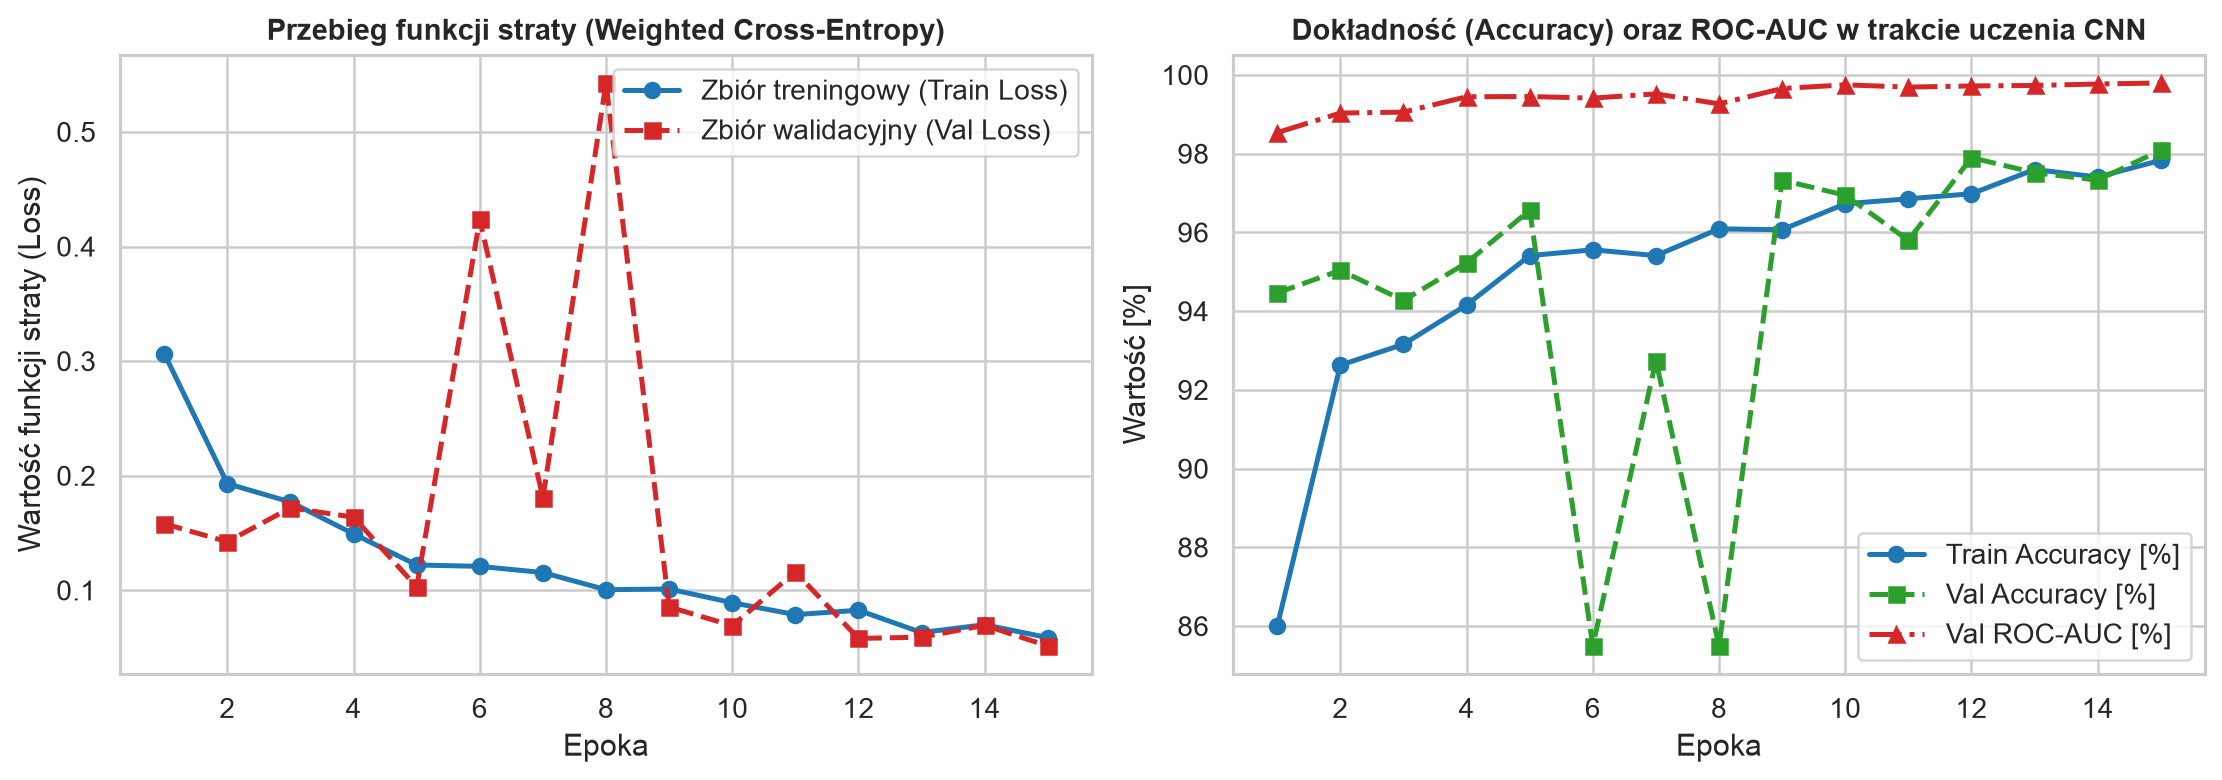

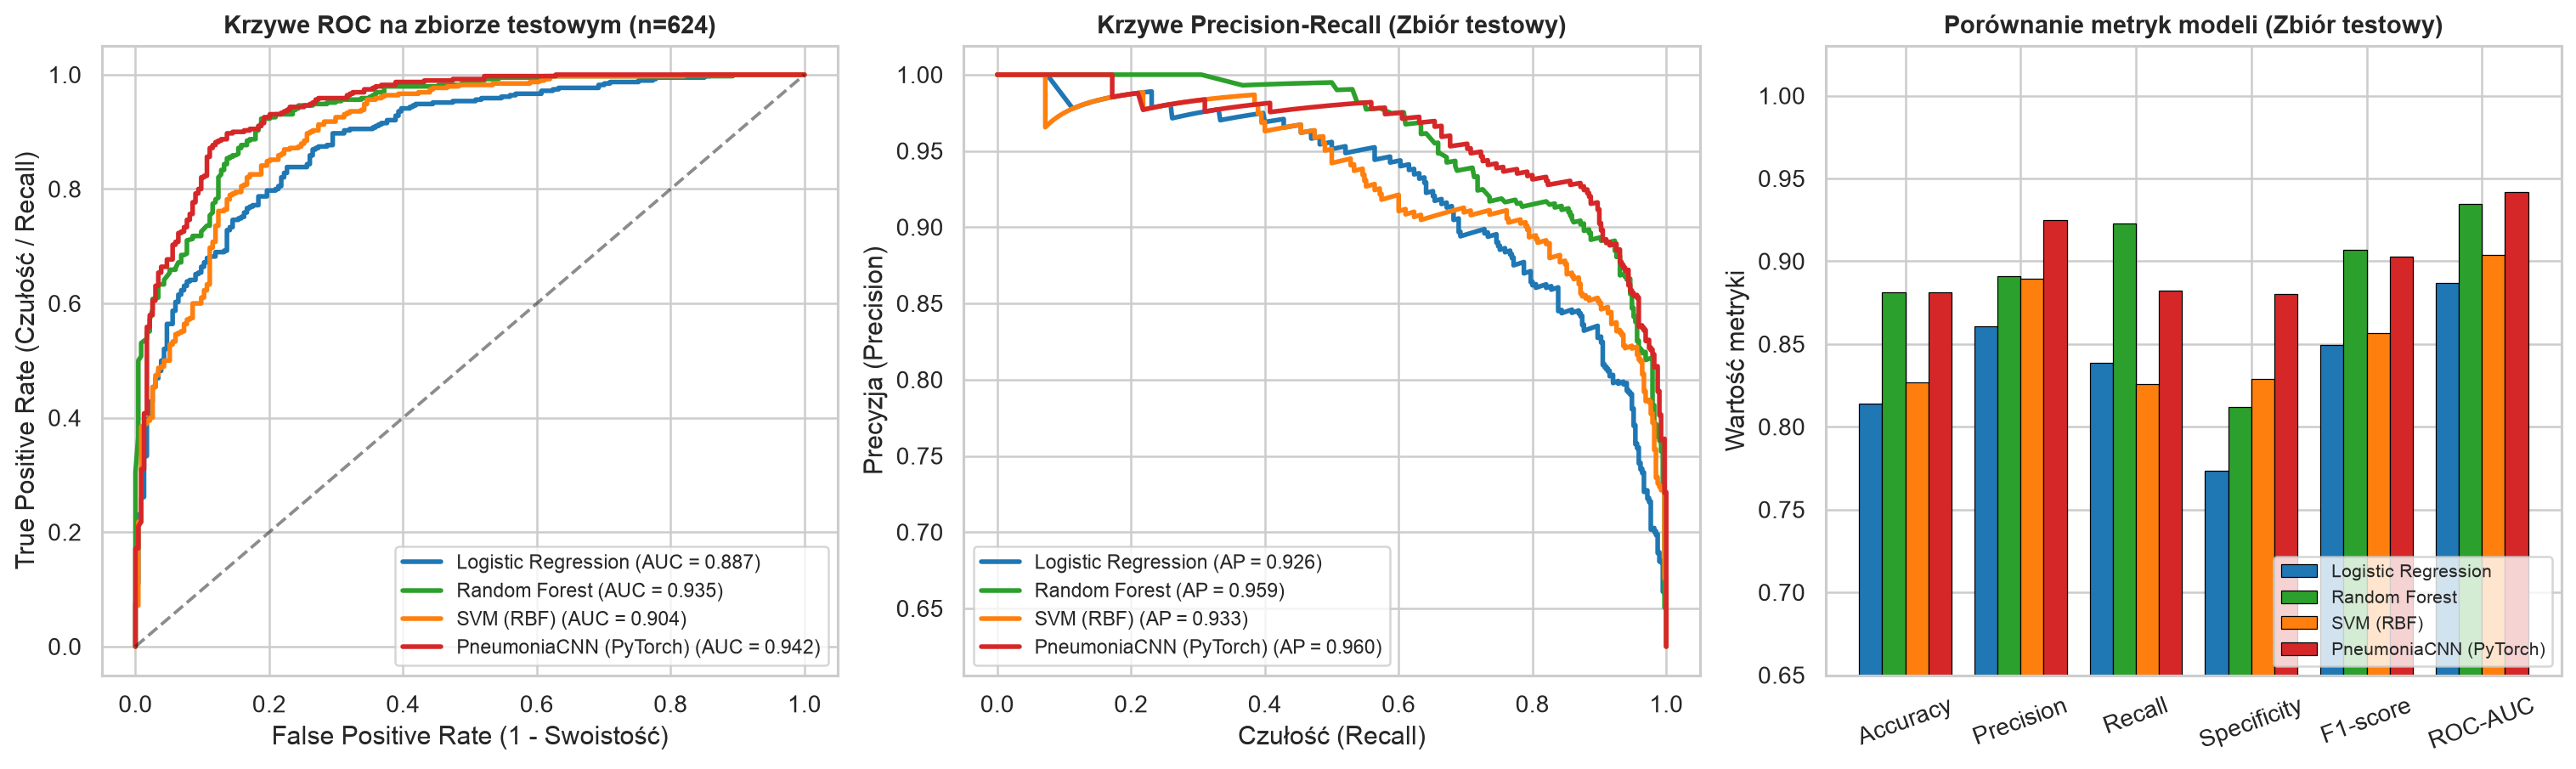

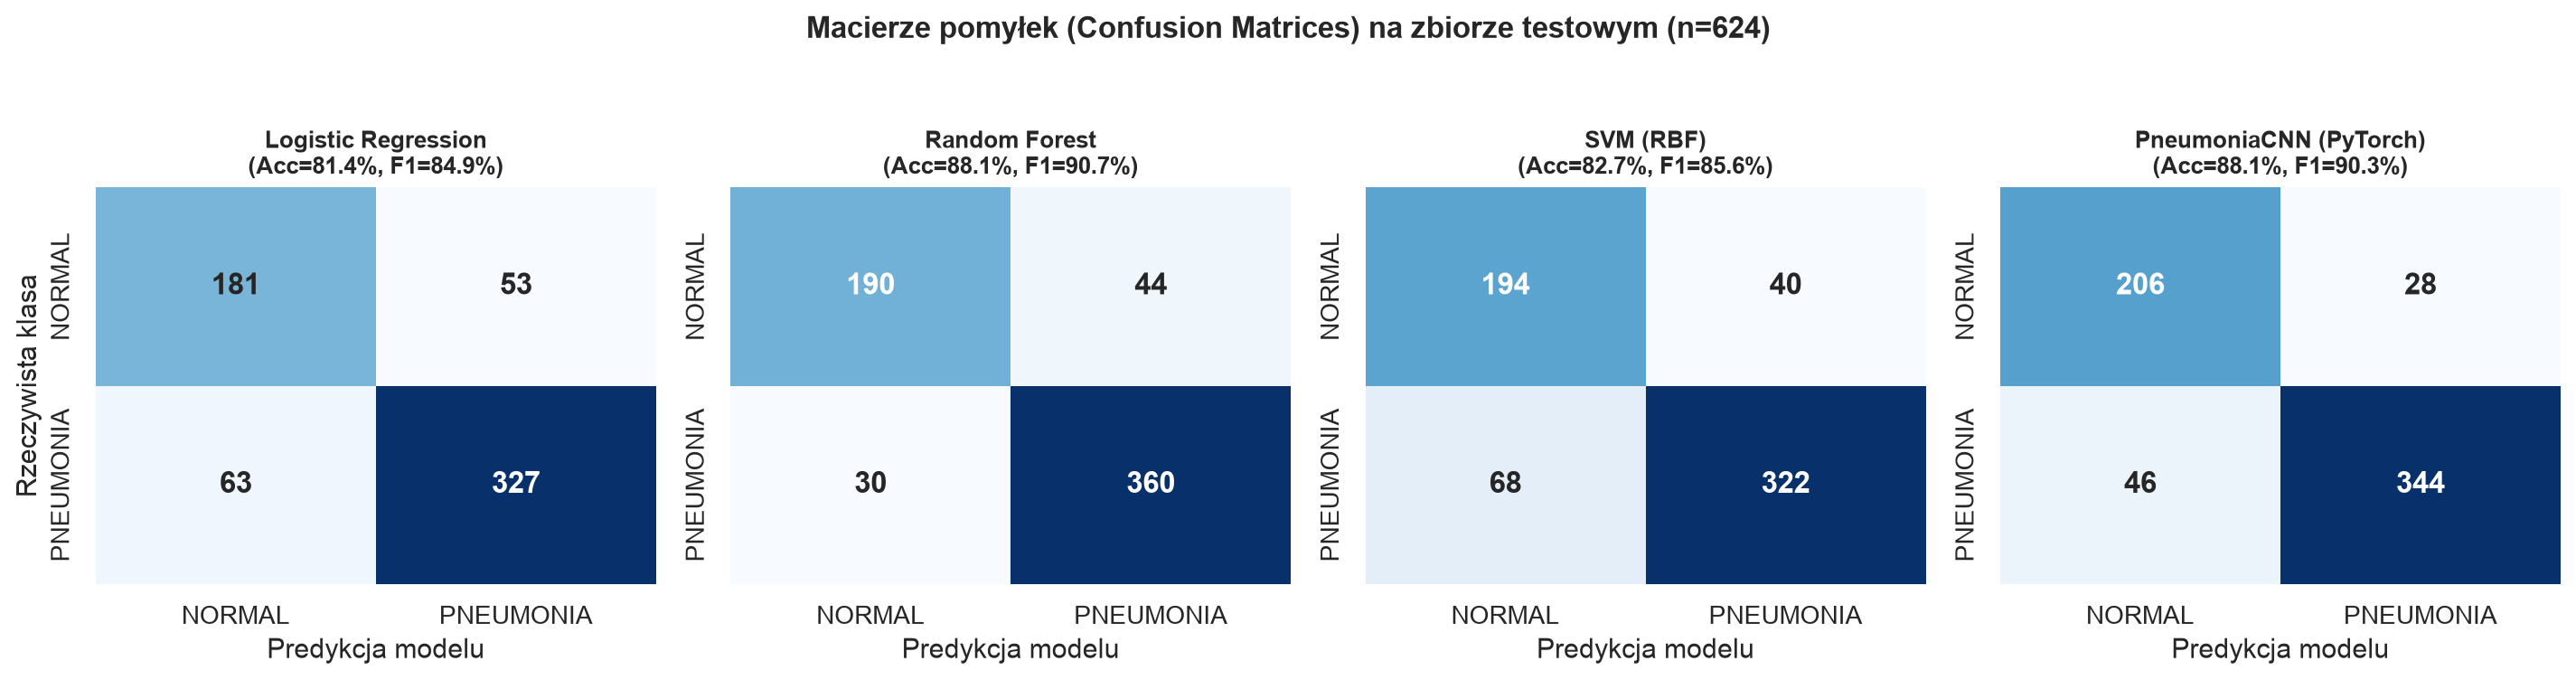

In [6]:
display(IPyImage(filename=str(FIGURES_DIR / 'fig7_cnn_training_curves.png')))
display(IPyImage(filename=str(FIGURES_DIR / 'fig5_model_comparison_roc_pr.png')))
display(IPyImage(filename=str(FIGURES_DIR / 'fig6_confusion_matrices.png')))

## 5. Wyjaśnialność Modeli (XAI: Feature Importance + Grad-CAM) oraz Analiza Błędów
Poniżej przedstawiono dwuwymiarowe mapy istotności pikseli (Random Forest oraz odwrotna transformacja wag Regresji Logistycznej przez PCA), ranking cech domenowych oraz mapy cieplne **Grad-CAM** wygenerowane z ostatniego bloku konwolucyjnego sieci `PneumoniaCNN`.

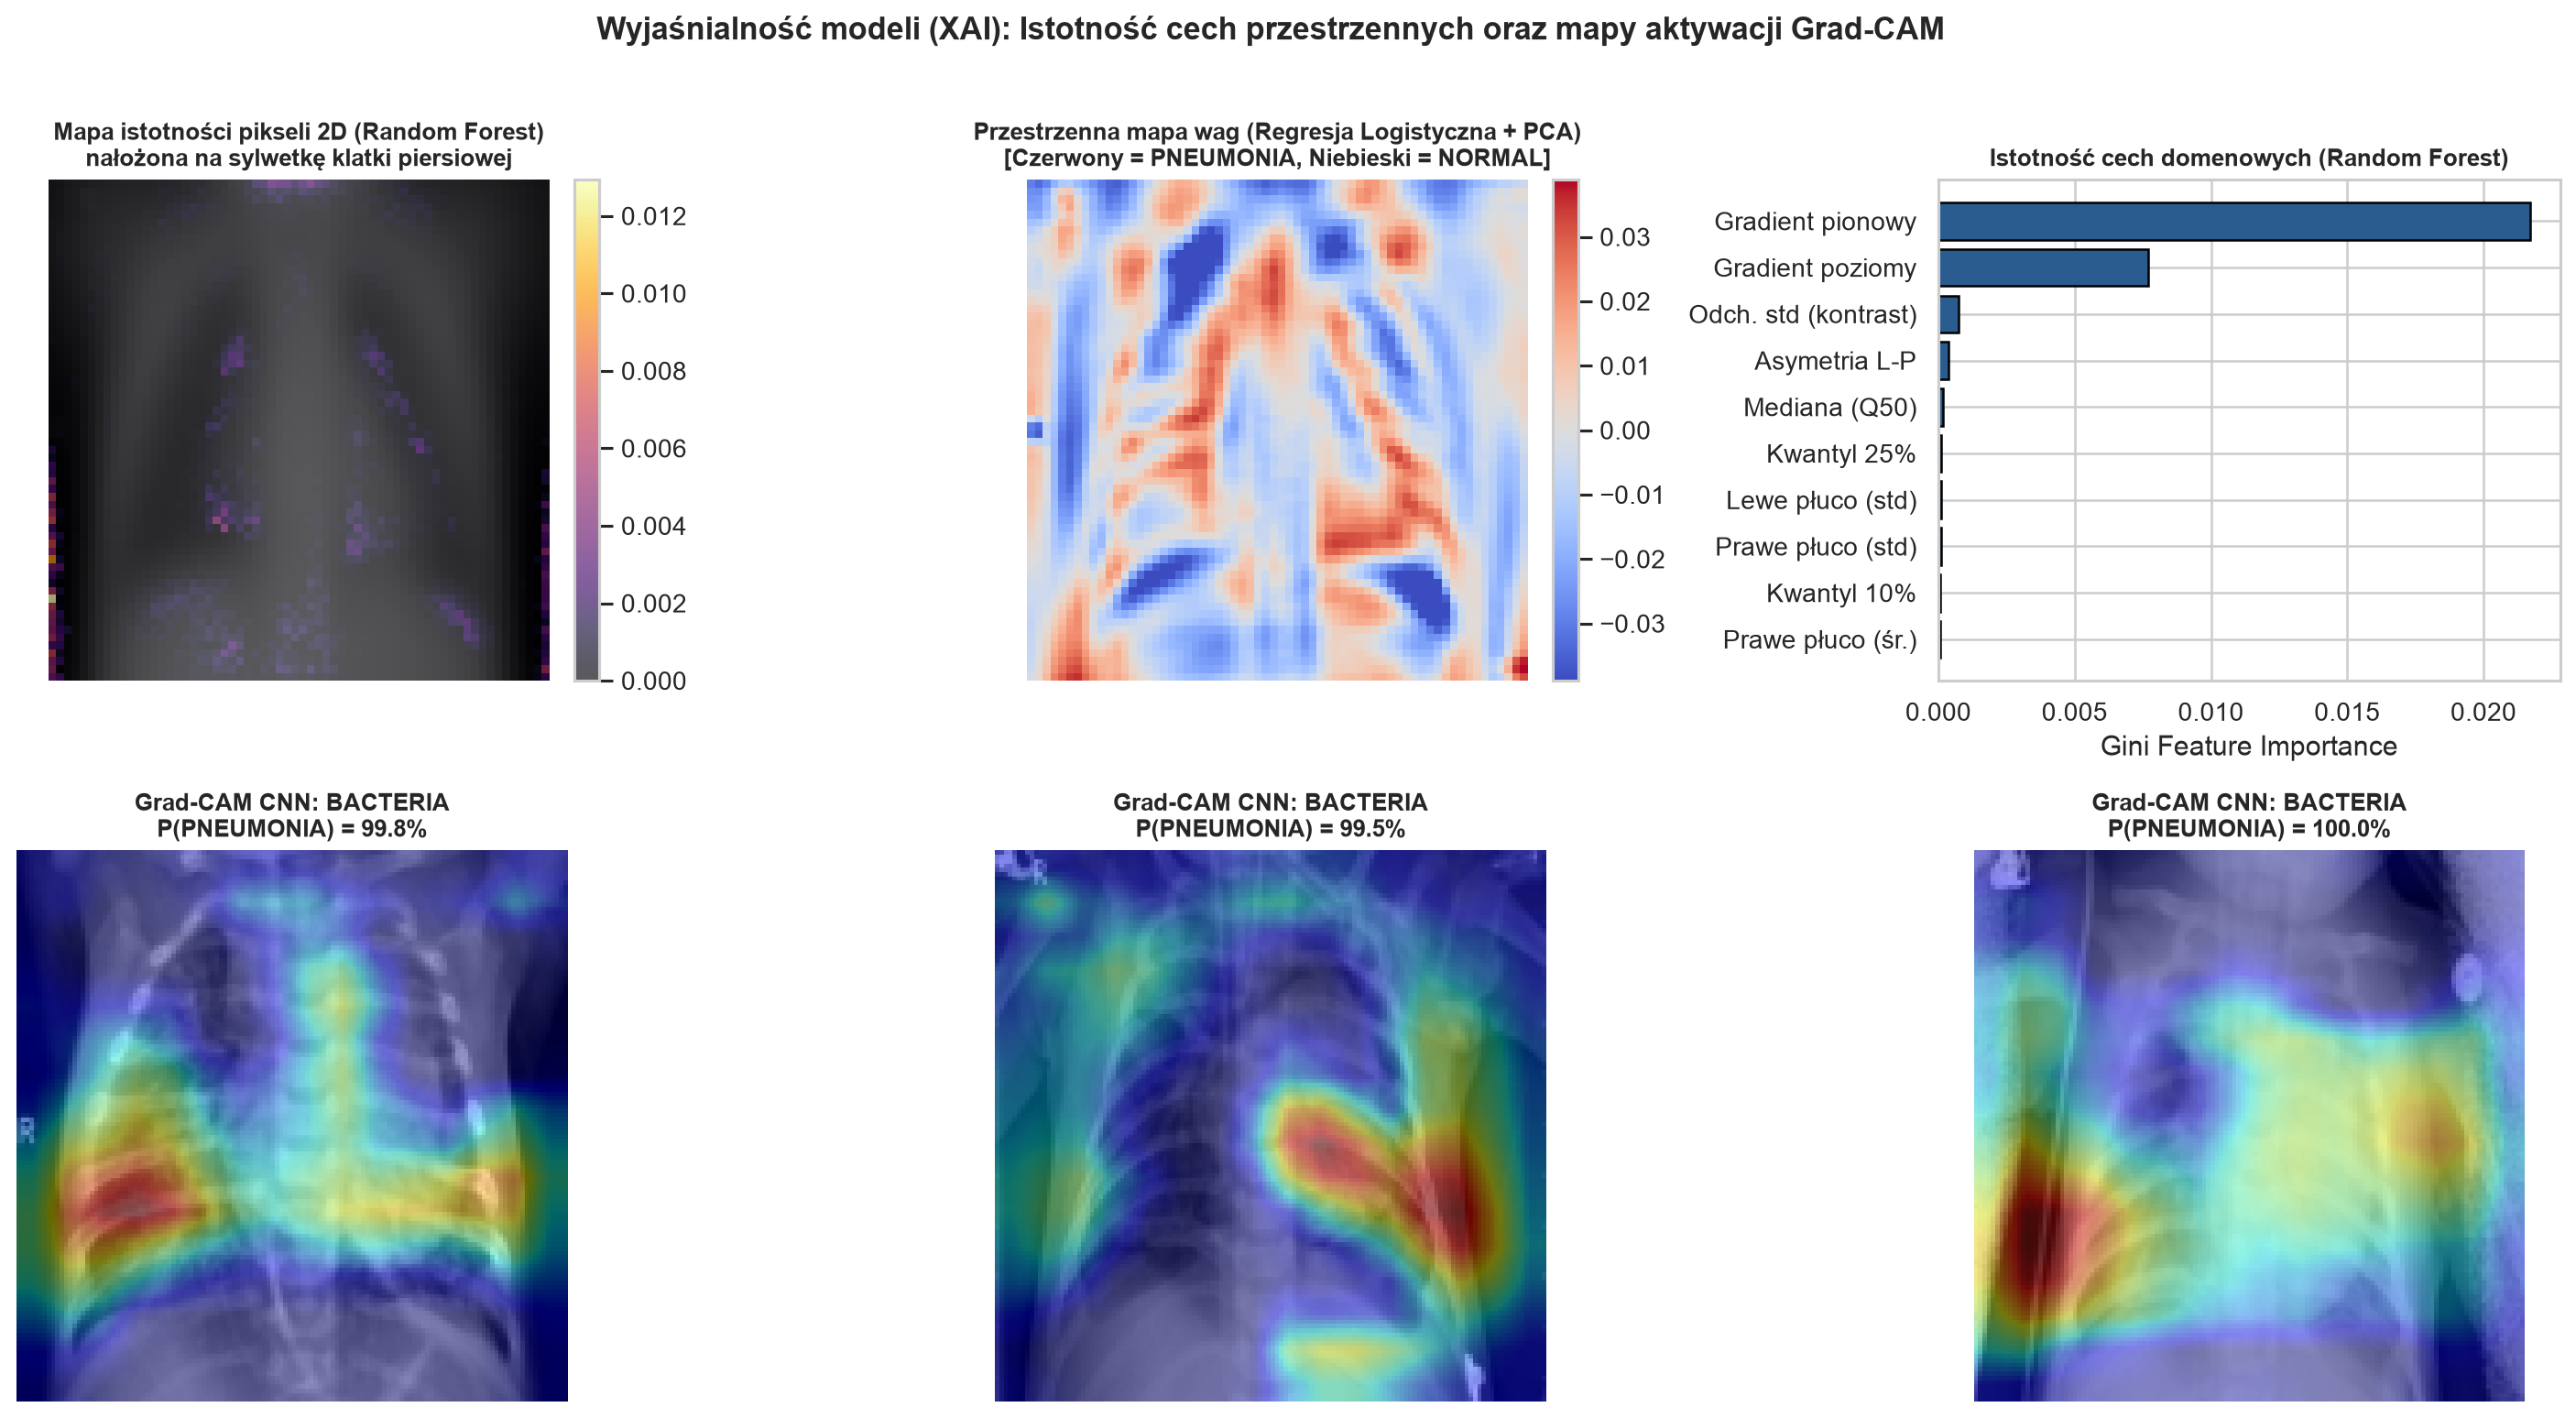

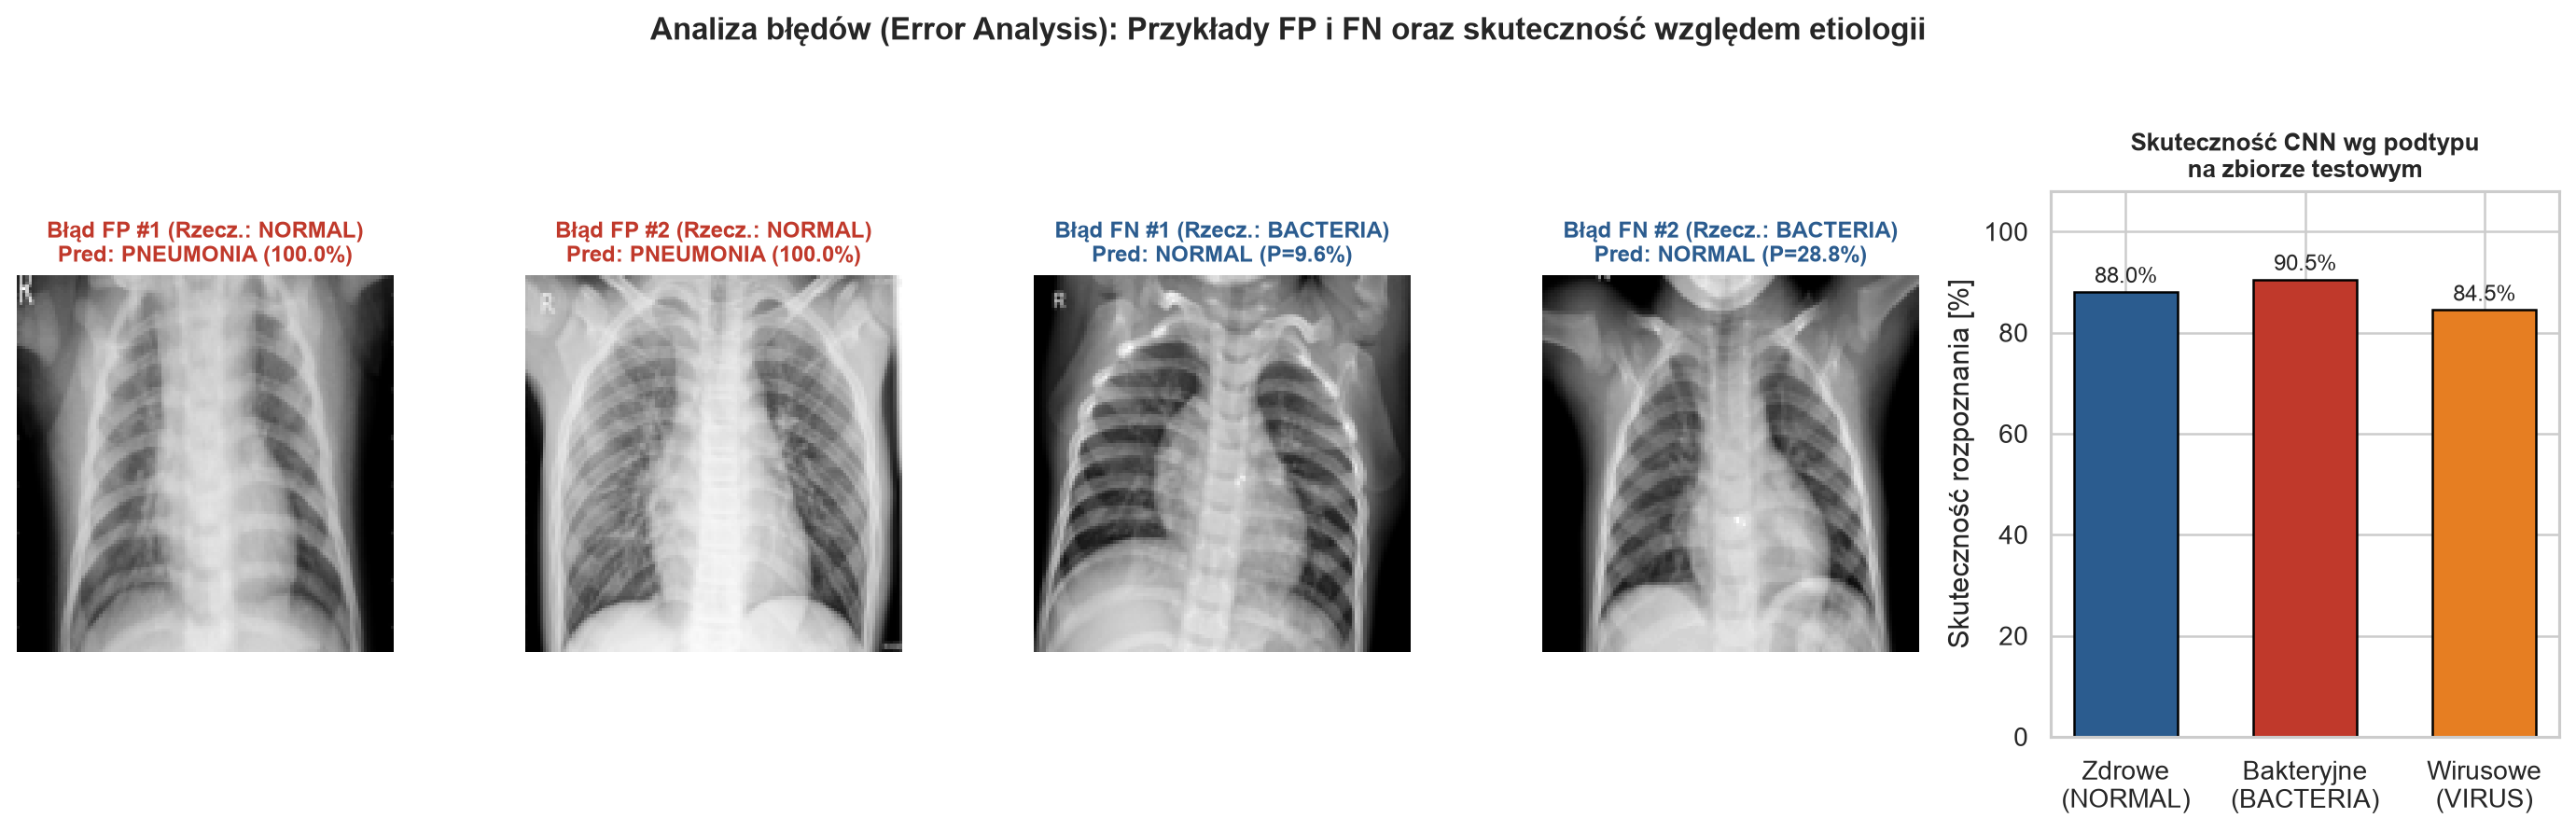

In [7]:
display(IPyImage(filename=str(FIGURES_DIR / 'fig8_explainability_gradcam_importance.png')))
display(IPyImage(filename=str(FIGURES_DIR / 'fig9_error_analysis.png')))

## 6. Implementacja – Interfejs diagnostyczny Streamlit (`app.py`)
Aplikację webową można uruchomić lokalnie poleceniem:
```bash
uv run streamlit run app.py
```
Poniżej widoczny jest wygenerowany podgląd działania panelu diagnostycznego dla pacjenta z bakteryjnym zapaleniem płuc oraz pacjenta zdrowego.

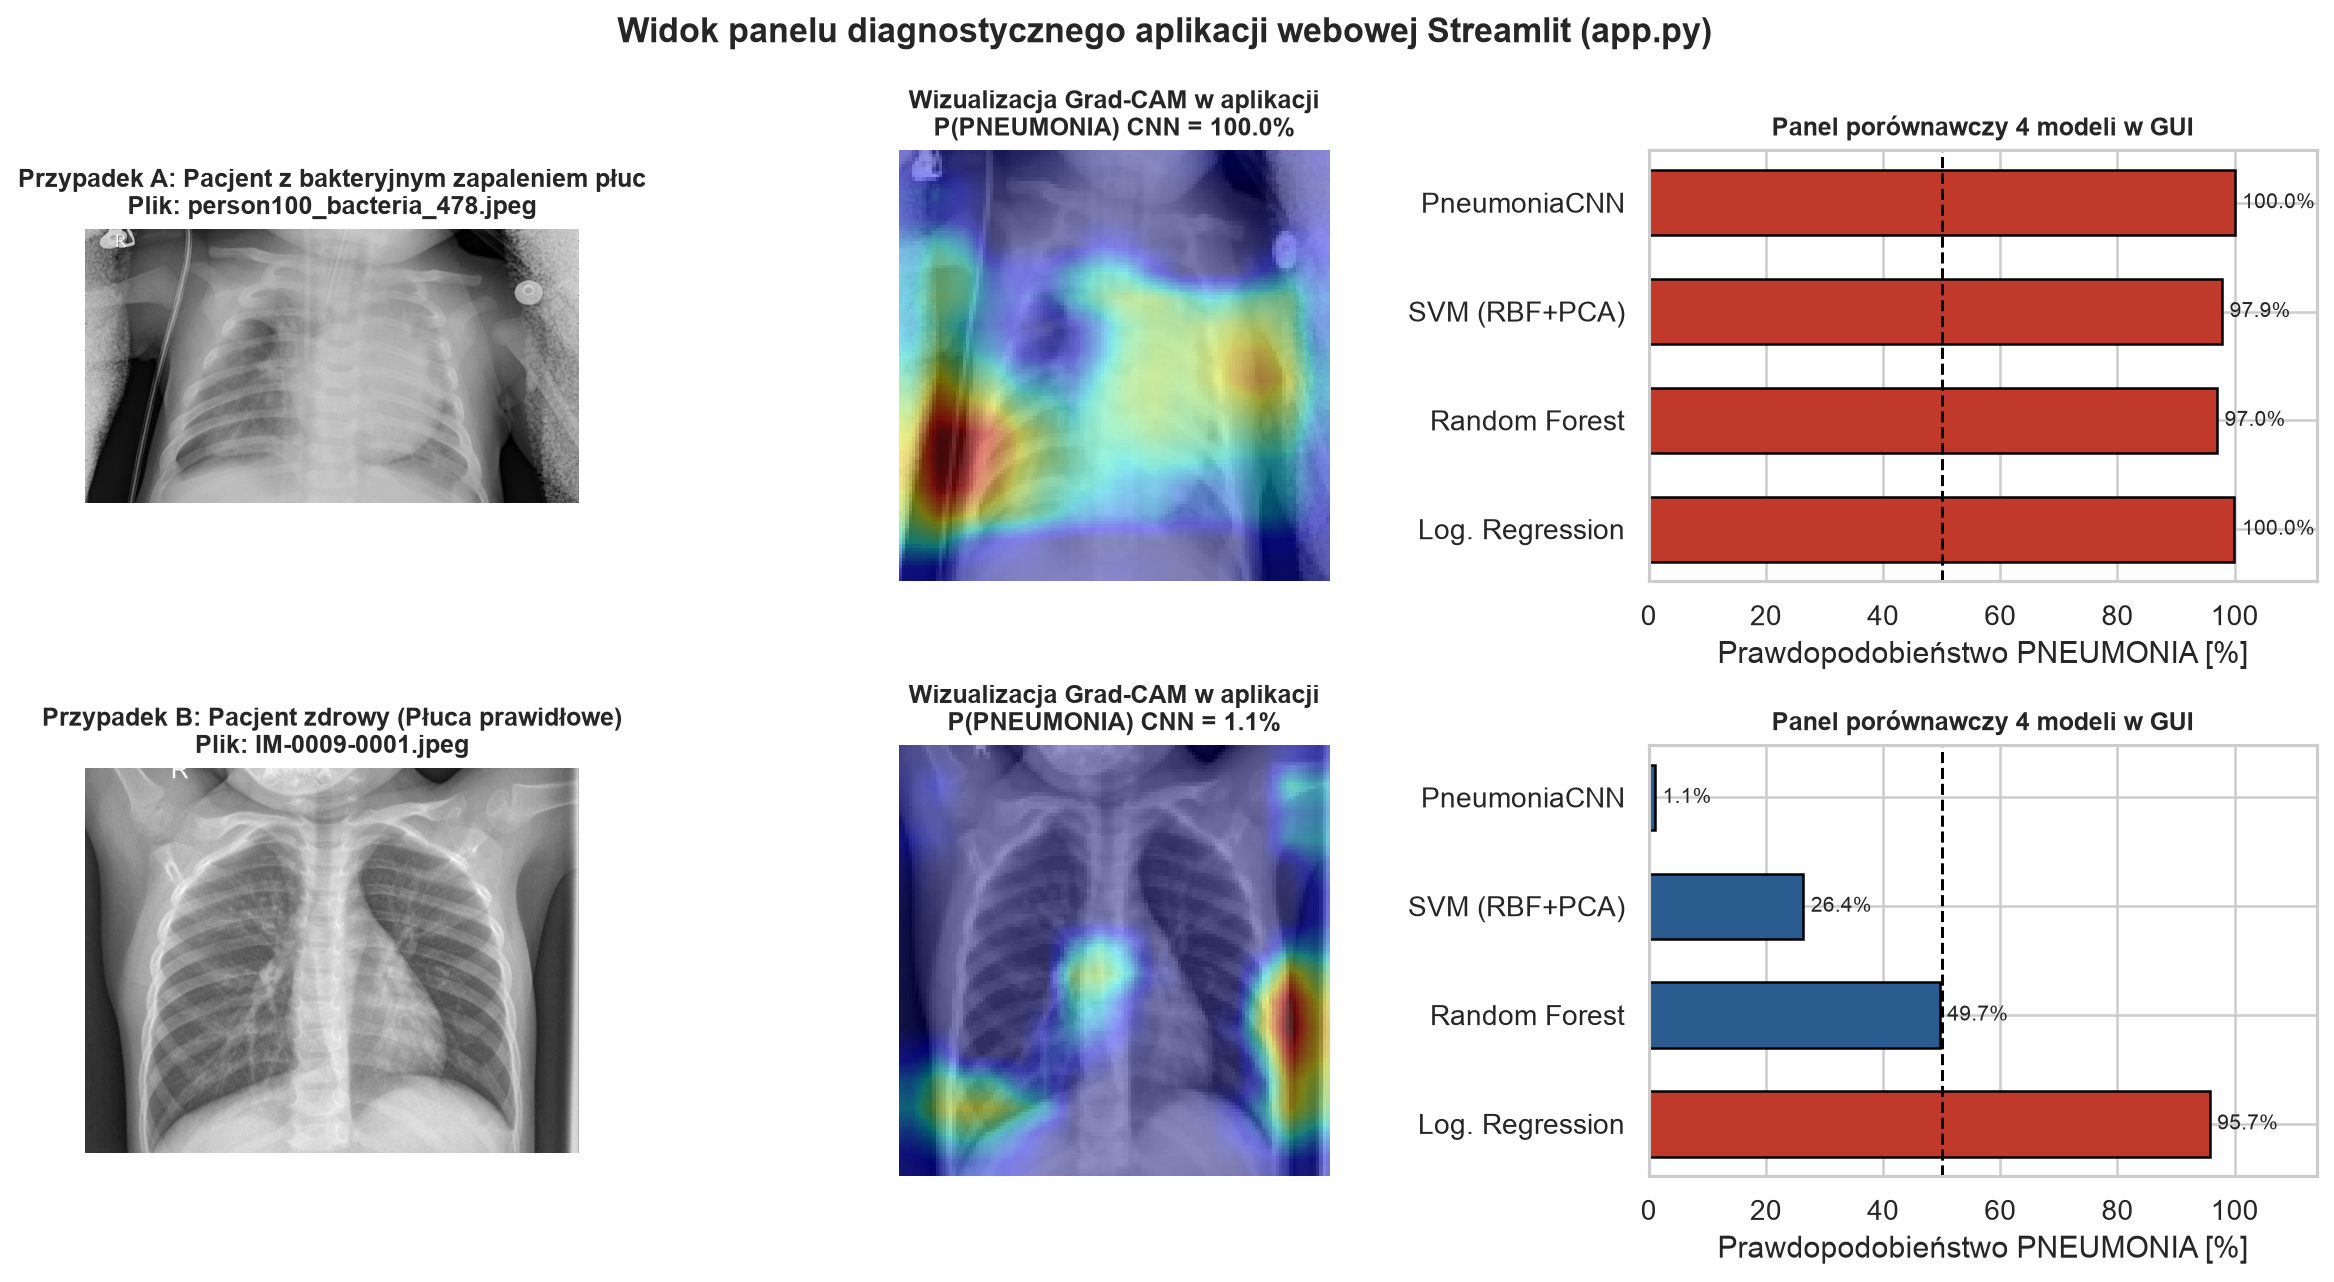

In [8]:
display(IPyImage(filename=str(FIGURES_DIR / 'fig10_ui_preview.png')))